[Batch GD] Test RMSE = 4.4105
[sklearn LR] Test RMSE = 4.4105
Difference (GD - sklearn) = 0.000000
[Mini-batch GD] Test RMSE = 4.4190


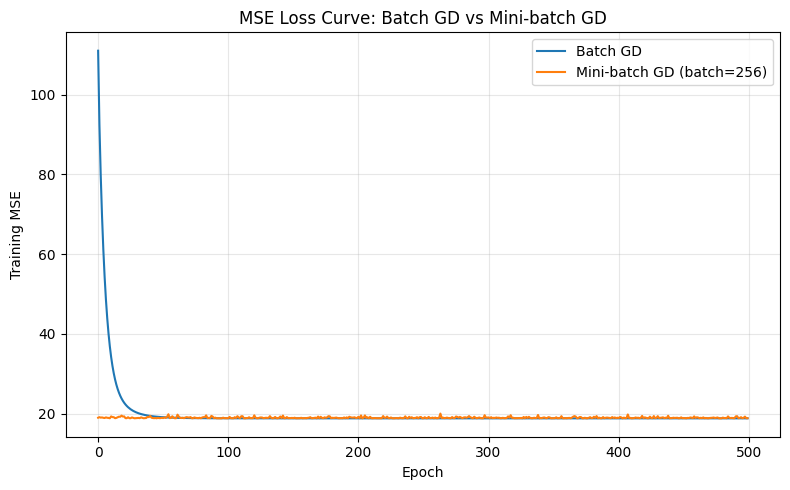


=== RMSE Comparison ===
Method                 Test RMSE
Batch GD                  4.4105
Mini-batch GD             4.4190
sklearn LinearReg         4.4105


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error


# ============================================================
# STEP 1: LOAD DATA

df = pd.read_csv("/content/placement_predict_50k Dataset.csv")

FEATURES = [
    "CGPA",
    "AttendancePercent",
    "Internships",
    "Projects",
    "Workshops",
    "Certifications",
    "Publications",
    "AptitudeTestScore",
    "SoftSkillsRating",
    "CodingTestScore",
    "MockInterviewScore",
    "ExtraCurricular",
]

TARGET = "Salary Package"

data = df[FEATURES + [TARGET]].copy()

# Fill missing feature values with median
data[FEATURES] = data[FEATURES].fillna(data[FEATURES].median())

X = data[FEATURES].values
y = data[TARGET].values.reshape(-1, 1)


# ============================================================
# STEP 2: TRAIN/TEST SPLIT + SCALING
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

n_samples, n_features = X_train_s.shape

# Add bias/intercept column
X_train_b = np.hstack([
    np.ones((n_samples, 1)),
    X_train_s
])

X_test_b = np.hstack([
    np.ones((X_test_s.shape[0], 1)),
    X_test_s
])


# ============================================================
# STEP 3: BATCH GRADIENT DESCENT
# ============================================================

def compute_mse(X, y, theta):
    preds = X @ theta
    errors = preds - y
    return np.mean(errors ** 2)


def batch_gradient_descent(X, y, lr=0.05, n_epochs=500):

    m, n = X.shape

    # Initialize weights with zeros
    theta = np.zeros((n, 1))

    loss_history = []

    for epoch in range(n_epochs):

        # Predictions
        preds = X @ theta

        # Errors
        errors = preds - y

        # Gradient
        gradient = (2 / m) * (X.T @ errors)

        # Update weights
        theta -= lr * gradient

        # Store loss
        loss_history.append(
            compute_mse(X, y, theta)
        )

    return theta, loss_history


theta_gd, loss_history_gd = batch_gradient_descent(
    X_train_b,
    y_train,
    lr=0.05,
    n_epochs=500
)

rmse_gd = np.sqrt(
    compute_mse(X_test_b, y_test, theta_gd)
)

print(f"[Batch GD] Test RMSE = {rmse_gd:.4f}")


# ============================================================
# STEP 4: SKLEARN LINEAR REGRESSION
# ============================================================

sk_model = LinearRegression()

sk_model.fit(
    X_train_s,
    y_train
)

y_pred_sk = sk_model.predict(X_test_s)

rmse_sklearn = np.sqrt(
    mean_squared_error(y_test, y_pred_sk)
)

print(
    f"[sklearn LR] Test RMSE = {rmse_sklearn:.4f}"
)

print(
    f"Difference (GD - sklearn) = "
    f"{rmse_gd - rmse_sklearn:.6f}"
)


# ============================================================
# STEP 5: MINI-BATCH GRADIENT DESCENT
# ============================================================

def mini_batch_gradient_descent(
    X,
    y,
    lr=0.05,
    n_epochs=500,
    batch_size=256,
    seed=42
):

    m, n = X.shape

    theta = np.zeros((n, 1))

    loss_history = []

    rng = np.random.default_rng(seed)

    for epoch in range(n_epochs):

        # Shuffle data
        indices = rng.permutation(m)

        X_shuffled = X[indices]
        y_shuffled = y[indices]

        # Process mini-batches
        for start in range(0, m, batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            # Predictions
            preds = X_batch @ theta

            # Errors
            errors = preds - y_batch

            # Gradient
            gradient = (
                2 / X_batch.shape[0]
            ) * (X_batch.T @ errors)

            # Update weights
            theta -= lr * gradient

        # Calculate loss using full training set
        loss_history.append(
            compute_mse(X, y, theta)
        )

    return theta, loss_history


theta_mb, loss_history_mb = mini_batch_gradient_descent(
    X_train_b,
    y_train,
    lr=0.05,
    n_epochs=500,
    batch_size=256
)

rmse_mb = np.sqrt(
    compute_mse(X_test_b, y_test, theta_mb)
)

print(
    f"[Mini-batch GD] Test RMSE = {rmse_mb:.4f}"
)


# ============================================================
# STEP 6: PLOT LOSS CURVES
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    loss_history_gd,
    label="Batch GD"
)

plt.plot(
    loss_history_mb,
    label="Mini-batch GD (batch=256)"
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE")

plt.title(
    "MSE Loss Curve: Batch GD vs Mini-batch GD"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "loss_curve.png",
    dpi=150
)

plt.show()


# ============================================================
# STEP 7: SUMMARY TABLE
# ============================================================

print("\n=== RMSE Comparison ===")

print(
    f"{'Method':<20}{'Test RMSE':>12}"
)

print(
    f"{'Batch GD':<20}{rmse_gd:>12.4f}"
)

print(
    f"{'Mini-batch GD':<20}{rmse_mb:>12.4f}"
)

print(
    f"{'sklearn LinearReg':<20}{rmse_sklearn:>12.4f}"
)



Dataset:
    Gender Stream  Internships  AptitudeScore  CGPA PlacementStatus CGPA_Tier
0     Male    CSE            2             80   8.5          Placed      High
1   Female    ECE            1             72   7.2          Placed    Medium
2     Male    CSE            3             88   9.0          Placed      High
3   Female    EEE            0             60   6.5      Not Placed       Low
4     Male    CSE            2             85   8.8          Placed      High
5   Female    ECE            1             70   7.0      Not Placed    Medium
6     Male   MECH            0             55   5.9      Not Placed       Low
7   Female    CSE            3             90   9.1          Placed      High
8     Male    ECE            2             76   7.8          Placed    Medium
9   Female    CSE            4             92   9.3          Placed      High
10    Male    EEE            1             68   6.8      Not Placed       Low
11  Female    CSE            3             86   8.7    

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(



MODEL EVALUATION
Training Accuracy : 1.0
Validation Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

  Not Placed       1.00      1.00      1.00         1
      Placed       1.00      1.00      1.00         3

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



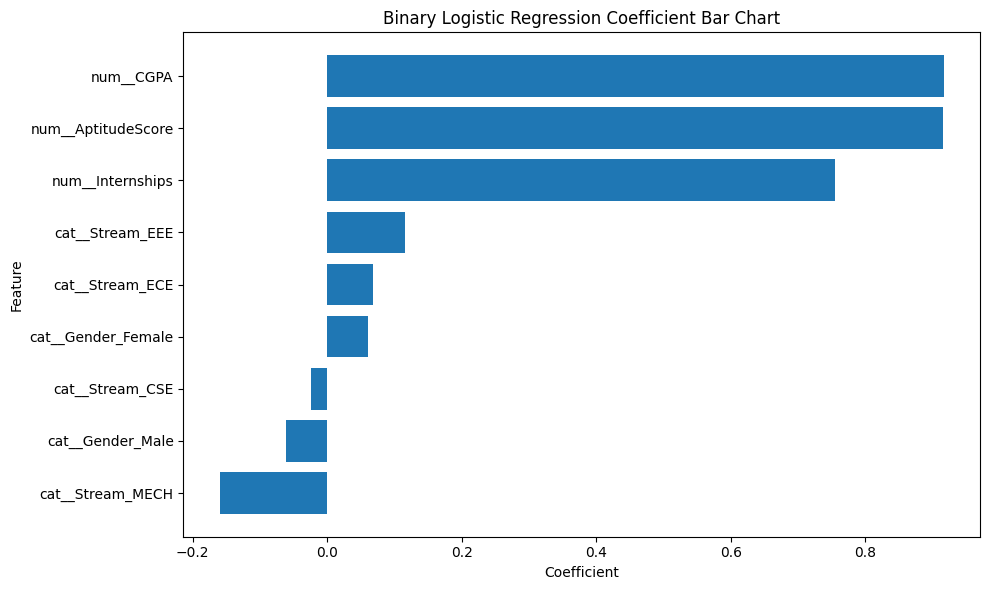

In [ ]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report


# ============================================================
# DATASET
# ============================================================

data = {
    'Gender': [
        'Male','Female','Male','Female','Male',
        'Female','Male','Female','Male','Female',
        'Male','Female','Male','Female','Male',
        'Female','Male','Female','Male','Female'
    ],

    'Stream': [
        'CSE','ECE','CSE','EEE','CSE',
        'ECE','MECH','CSE','ECE','CSE',
        'EEE','CSE','MECH','ECE','CSE',
        'EEE','CSE','ECE','CSE','EEE'
    ],

    'Internships': [
        2,1,3,0,2,
        1,0,3,2,4,
        1,3,0,2,4,
        1,0,3,2,4
    ],

    'AptitudeScore': [
        80,72,88,60,85,
        70,55,90,76,92,
        68,86,58,78,95,
        73,62,89,81,91
    ],

    'CGPA': [
        8.5,7.2,9.0,6.5,8.8,
        7.0,5.9,9.1,7.8,9.3,
        6.8,8.7,6.2,7.9,9.5,
        7.4,6.5,8.9,8.2,9.0
    ],

    'PlacementStatus': [
        'Placed','Placed','Placed','Not Placed','Placed',
        'Not Placed','Not Placed','Placed','Placed','Placed',
        'Not Placed','Placed','Not Placed','Placed','Placed',
        'Placed','Not Placed','Placed','Placed','Placed'
    ]
}

df = pd.DataFrame(data)


# ============================================================
# CREATE CGPA TIER
# ============================================================

def create_cgpa_tier(cgpa):

    if cgpa < 7:
        return 'Low'

    elif cgpa < 8.5:
        return 'Medium'

    else:
        return 'High'


df['CGPA_Tier'] = df['CGPA'].apply(create_cgpa_tier)


print("Dataset:")
print(df)

print("\nCGPA Tier:")
print(df[['CGPA', 'CGPA_Tier']])


# ============================================================
# FEATURES
# ============================================================

features = [
    'Gender',
    'Stream',
    'Internships',
    'AptitudeScore',
    'CGPA'
]

X = df[features]


categorical_features = [
    'Gender',
    'Stream'
]

numerical_features = [
    'Internships',
    'AptitudeScore',
    'CGPA'
]


# ============================================================
# OHE + SCALING PIPELINE
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),

        (
            'num',
            StandardScaler(),
            numerical_features
        )
    ]
)


# ============================================================
# EVALUATION FUNCTION
# ============================================================

def evaluate_classifier(
    model,
    X_train,
    y_train,
    X_val,
    y_val
):

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)

    val_pred = model.predict(X_val)

    train_accuracy = accuracy_score(
        y_train,
        train_pred
    )

    val_accuracy = accuracy_score(
        y_val,
        val_pred
    )

    print("\n" + "=" * 60)
    print("MODEL EVALUATION")
    print("=" * 60)

    print(
        "Training Accuracy :",
        train_accuracy
    )

    print(
        "Validation Accuracy:",
        val_accuracy
    )

    print("\nClassification Report:")

    print(
        classification_report(
            y_val,
            val_pred
        )
    )


# ============================================================
# MODEL 1
# BINARY LOGISTIC REGRESSION
# Target = PlacementStatus
# ============================================================

y_placement = df['PlacementStatus']


X_train, X_val, y_train, y_val = train_test_split(
    X,
    y_placement,
    test_size=0.2,
    random_state=42,
    stratify=y_placement
)


binary_lr = Pipeline(
    steps=[
        (
            'preprocessor',
            preprocessor
        ),

        (
            'classifier',
            LogisticRegression(
                max_iter=1000
            )
        )
    ]
)


print("\n\nMODEL 1: BINARY LOGISTIC REGRESSION")

evaluate_classifier(
    binary_lr,
    X_train,
    y_train,
    X_val,
    y_val
)


# ============================================================
# MODEL 2
# MULTINOMIAL LOGISTIC REGRESSION
# Target = CGPA_Tier
# ============================================================

y_cgpa = df['CGPA_Tier']


X_train2, X_val2, y_train2, y_val2 = train_test_split(
    X,
    y_cgpa,
    test_size=0.2,
    random_state=42,
    stratify=y_cgpa
)


multinomial_lr = Pipeline(
    steps=[
        (
            'preprocessor',
            preprocessor
        ),

        (
            'classifier',
            LogisticRegression(
                max_iter=1000,
                multi_class='multinomial'
            )
        )
    ]
)


print("\n\nMODEL 2: MULTINOMIAL LOGISTIC REGRESSION")

evaluate_classifier(
    multinomial_lr,
    X_train2,
    y_train2,
    X_val2,
    y_val2
)


# ============================================================
# MODEL 3
# RANDOM FOREST
# Target = PlacementStatus
# ============================================================

random_forest = Pipeline(
    steps=[
        (
            'preprocessor',
            preprocessor
        ),

        (
            'classifier',
            RandomForestClassifier(
                n_estimators=100,
                random_state=42
            )
        )
    ]
)


print("\n\nMODEL 3: RANDOM FOREST")

evaluate_classifier(
    random_forest,
    X_train,
    y_train,
    X_val,
    y_val
)


# ============================================================
# COEFFICIENT BAR CHART
# ============================================================

feature_names = binary_lr.named_steps[
    'preprocessor'
].get_feature_names_out()


coefficients = binary_lr.named_steps[
    'classifier'
].coef_[0]


coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})


coef_df = coef_df.sort_values(
    by='Coefficient'
)


plt.figure(figsize=(10, 6))

plt.barh(
    coef_df['Feature'],
    coef_df['Coefficient']
)

plt.xlabel('Coefficient')
plt.ylabel('Feature')

plt.title(
    'Binary Logistic Regression Coefficient Bar Chart'
)

plt.tight_layout()

plt.show()